# Dataset Review 1/3 — causRCA (CNC Vertical Lathe)

**Purpose.** Evidence-based evaluation of the causRCA dataset as a candidate for a thesis on
causal AI in predictive maintenance, following the workflow:

> Causal Discovery → Root Cause Analysis → Interventions → Counterfactual XAI → Actionable Recommendations

**Dataset.** Mehling, C. W., Pieper, S., Lüke, T. (2025). *causRCA: Real-World Dataset for Causal
Discovery and Root Cause Analysis in Machinery* (v1.0.0). Zenodo.
[doi:10.5281/zenodo.15876410](https://doi.org/10.5281/zenodo.15876410) — Apache-2.0.
Companion paper: Mehling et al. (2025), *Procedia CIRP* (CIRPe), "Enabling Joint Benchmarking of
Automated Root Cause Analysis and Causal Discovery in Manufacturing Using the causRCA Dataset."
Code: [github.com/causalgraph/causRCA](https://github.com/causalgraph/causRCA).

**What it is.** Time-series event logs from the CNC control (OPC UA) of an industrial vertical
lathe: 170 recordings of normal factory operation plus 100 fault recordings produced on a
hardware-in-the-loop digital twin, where faults were *injected by manipulating known variables*.
Ships with an expert-derived causal graph over all 92 variables as ground truth.

**Review questions** (the unknowns this notebook answers with evidence):
1. How complete is the documentation?
2. How clean is the data?
3. How easy is preprocessing?
4. Does it support intervention experiments?
5. Is the temporal resolution sufficient for PCMCI?

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from causalpdm import causrca
from causalpdm.config import CAUSRCA_RAW

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
RNG = np.random.default_rng(42)

## 1. Dataset inventory

The dataset has three parts: `real_op/` (normal operation), `dig_twin/` (fault experiments in
three subsystem groups), and `expert_graph/` (ground-truth causal graph).

In [2]:
real_op_files = causrca.list_real_op_files()
fault_runs = causrca.list_fault_runs()

total_mb = sum(f.stat().st_size for f in CAUSRCA_RAW.rglob("*") if f.is_file()) / 1e6
print(f"Total size on disk       : {total_mb:.0f} MB")
print(f"Normal-operation logs    : {len(real_op_files)}")
print(f"Fault runs (digital twin): {len(fault_runs)}")
print(f"Fault scenarios          : {fault_runs['exp_id'].nunique()}")
print(f"Distinct diagnoses       : {fault_runs['diagnosis'].nunique()}")
fault_runs.groupby("group").agg(
    runs=("run", "size"),
    scenarios=("exp_id", "nunique"),
    diagnoses=("diagnosis", "nunique"),
)

Total size on disk       : 24 MB
Normal-operation logs    : 170
Fault runs (digital twin): 100
Fault scenarios          : 19
Distinct diagnoses       : 11


,runs,scenarios,diagnoses
group,,,
coolant,25,4,2
hydraulics,41,9,5
probe,34,6,4


## 2. General EDA

### 2.1 Data format and variable types

Recordings are **event logs in long format** — a row `(time_s, node, value, type)` is written
only when a variable *changes*. This is a change-of-value (CoV) log, not a regularly sampled
multivariate series, and is the single most important preprocessing fact about this dataset.

In [3]:
sample_log = causrca.load_event_log(real_op_files[0])
display(sample_log.head(8))
print(f"Events in this recording: {len(sample_log):,}  |  duration: {sample_log['time_s'].max():.0f} s")
print("\nEvent share by variable type:")
print(sample_log["type"].value_counts(normalize=True).round(3))

,time_s,node,value,type
0,0.0,CBC_Closed,True,Binary
1,0.0,CBC_close,True,Binary
2,0.0,CBC_isOpen,False,Binary
3,0.0,CBC_open,False,Binary
4,0.0,CLF_Filter_Ok,True,Binary
5,0.0,CLT_Level_lt_Min,False,Binary
6,0.0,ExU_On,True,Binary
7,0.0,ExU_isOff,False,Binary


Events in this recording: 3,326  |  duration: 524 s

Event share by variable type:
type
Continuous     0.382
Counter        0.234
Categorical    0.206
Binary         0.170
Alarm          0.008
Name: proportion, dtype: float64


In [4]:
nodes = causrca.load_node_table()
print(f"Variables in the system: {len(nodes)}")
print("\nBy role:")
print(nodes["type"].value_counts())
print("\nBy subsystem (top level of OPC UA path):")
print(nodes["path"].str.split("/").str[1].value_counts())
nodes.head(6)

Variables in the system: 92

By role:
type
Variable    74
Alarm       18
Name: count, dtype: int64

By subsystem (top level of OPC UA path):
path
WorkpieceSupply     18
Hydraulics          17
Coolant             15
MeasuringProbe      11
Monitoring           8
Spindle              8
Program              6
MovingSteadyRest     3
ExtractionUnit       2
Lubrication          2
Tool                 2
Name: count, dtype: int64


,id,path,label,type,io,datatype,examples,comment
0,1,Lathe/Coolant/Filter,CLF_A_700307,Alarm,NaN,bool,"True (=alarm active), False(=alarm inactive)",alarm that coolant filter is clogged
1,2,Lathe/Coolant/Filter,CLF_Filter_Ok,Variable,input,bool,"True, False",True = coolant filter for fine particles is in...
2,3,Lathe/Coolant/Fleece,F_A_700313,Alarm,NaN,bool,"True (=alarm active), False(=alarm inactive)",alarm that fleece supply in coolant is empty a...
3,4,Lathe/Coolant/Fleece,F_Filter_Ok,Variable,input,bool,"True, False",True = coolant fleece filter is Ok (not empty)...
4,5,Lathe/Coolant/HighPressurePump,HP_A_700304,Alarm,NaN,bool,"True (=alarm active), False(=alarm inactive)",alarm that coolant high pressure (HP) pump mot...
5,6,Lathe/Coolant/HighPressurePump,HP_Pump_isOff,Variable,input,bool,"True, False",True = high pressure pump for coolant is turne...


### 2.2 Recording length and event density

For temporal causal discovery we need to know how long the series are and how densely events
arrive. We profile every recording (170 normal + 100 fault).

In [5]:
def profile(paths, label):
    rows = []
    for p in paths:
        ev = causrca.load_event_log(p)
        rows.append({
            "file": p.name,
            "kind": label,
            "duration_s": ev["time_s"].max(),
            "n_events": len(ev),
            "n_variables": ev["node"].nunique(),
            "events_per_s": len(ev) / max(ev["time_s"].max(), 1e-9),
        })
    return pd.DataFrame(rows)

prof = pd.concat([
    profile(real_op_files, "normal"),
    profile(fault_runs["csv_path"], "fault"),
], ignore_index=True)

prof.groupby("kind")[["duration_s", "n_events", "n_variables", "events_per_s"]].describe().round(1).T

kind                 fault  normal
duration_s   count   100.0   170.0
             mean    222.2   581.9
             std      48.9    51.0
             min     140.4    80.1
             25%     190.1   590.6
             50%     218.8   599.5
             75%     247.5   599.9
             max     364.1   613.7
n_events     count   100.0   170.0
             mean   1058.0  2368.6
             std     161.6  1541.2
             min     677.0    78.0
             25%     985.0   551.2
             50%    1078.5  3311.0
             75%    1165.5  3626.2
             max    1414.0  4426.0
n_variables  count   100.0   170.0
             mean     54.6    74.1
             std       4.4     0.6
             min      47.0    73.0
             25%      50.8    74.0
             50%      55.0    74.0
             75%      57.0    74.0
             max      65.0    78.0
events_per_s count   100.0   170.0
             mean      4.9     4.0
             std       1.1     2.6
             min       3.1     0.1
             25%       4.2     0.9
             50%       4.7     5.6
             75%       5.6     6.1
             max       7.7     7.4

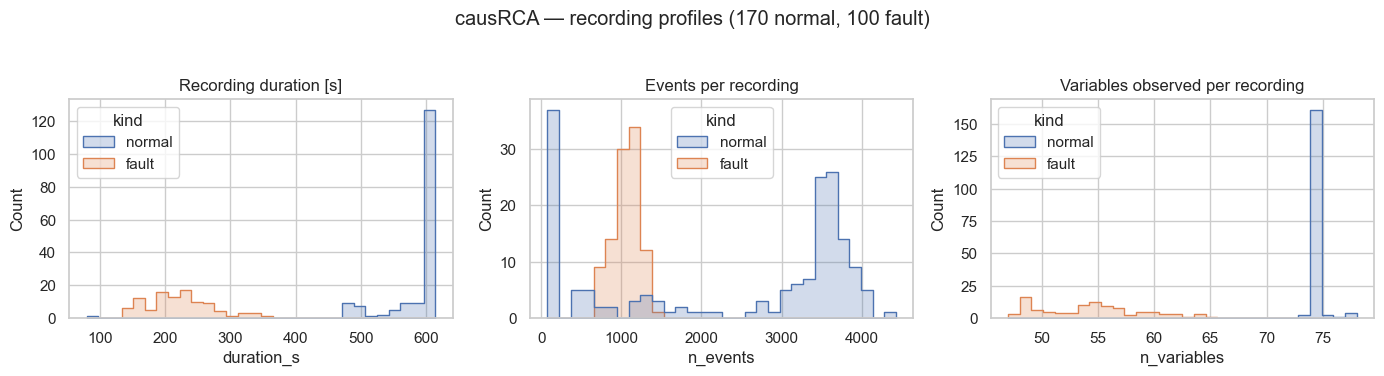

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, title in zip(
    axes,
    ["duration_s", "n_events", "n_variables"],
    ["Recording duration [s]", "Events per recording", "Variables observed per recording"],
):
    sns.histplot(data=prof, x=col, hue="kind", bins=30, ax=ax, element="step")
    ax.set_title(title)
fig.suptitle("causRCA — recording profiles (170 normal, 100 fault)", y=1.04)
plt.tight_layout()
plt.show()

### 2.3 Data cleanliness

We check for parse failures, duplicated events, non-monotonic timestamps and missing values
across all 270 recordings.

In [7]:
issues = []
for p in [*real_op_files, *fault_runs["csv_path"]]:
    ev = causrca.load_event_log(p)
    issues.append({
        "n_null": int(ev.isna().sum().sum()),
        "n_dup": int(ev.duplicated().sum()),
        "time_monotonic": bool(ev["time_s"].is_monotonic_increasing),
        "negative_time": bool((ev["time_s"] < 0).any()),
    })
issues = pd.DataFrame(issues)
print(f"Recordings checked                 : {len(issues)}")
print(f"Recordings with any missing values : {(issues['n_null'] > 0).sum()}")
print(f"Recordings with duplicate events   : {(issues['n_dup'] > 0).sum()}")
print(f"Recordings with non-monotonic time : {(~issues['time_monotonic']).sum()}")
print(f"Recordings with negative timestamps: {issues['negative_time'].sum()}")

Recordings checked                 : 270
Recordings with any missing values : 0
Recordings with duplicate events   : 0
Recordings with non-monotonic time : 0
Recordings with negative timestamps: 0


### 2.4 A fault run, visualised

One coolant-system run: the digital twin injects a fault (`manipulatedVars`) at a known time and
the ground truth (`causes.json`) records exactly when the cause started, when alarms fired and
when the diagnosis was reached. We plot the intervened variables and the triggered alarms.

Experiment  : exp_22 (coolant), run_1
Manipulated : ['HP_Pump_Ok', 'LT_Level_Ok']
Alarms      : ['HP_A_700304', 'LT_A_700317']
Diagnosis   : Leakage in coolant system.
Timing      : cause@106.9s -> alarm@155.5s -> diagnosis@180.5s


/Users/shwetabambal/Documents/myrepos/causalai-in-PdM/src/causalpdm/causrca.py:101: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .ffill()


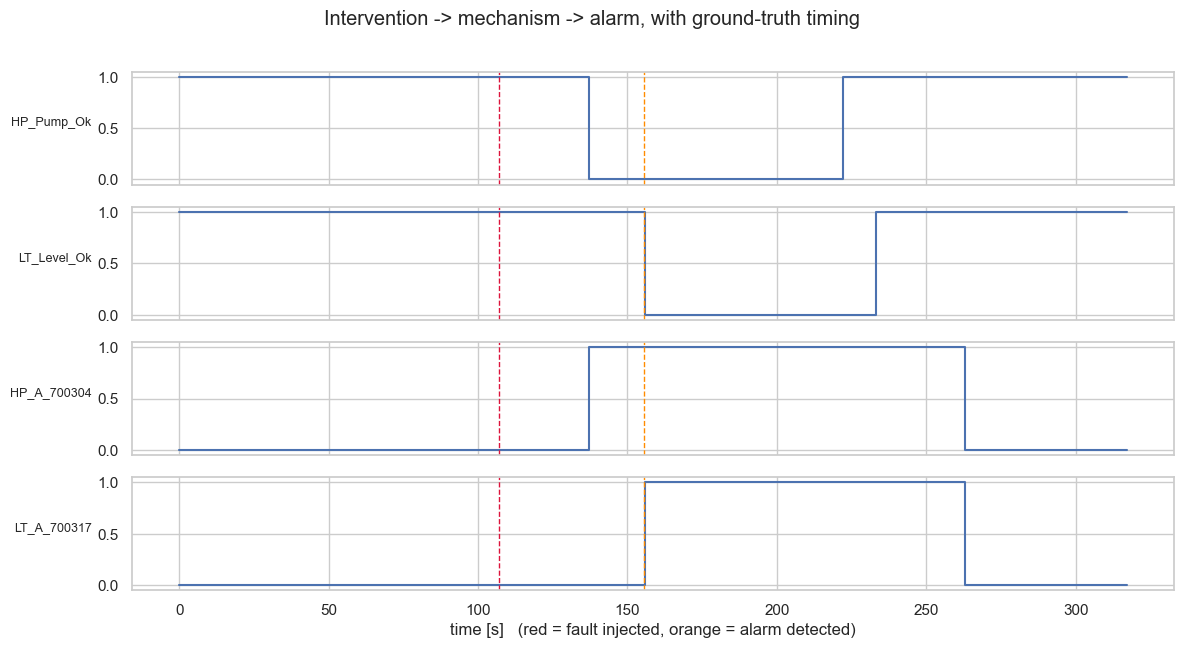

In [8]:
run = fault_runs.iloc[0]
print(f"Experiment  : {run['exp_id']} ({run['group']}), {run['run']}")
print(f"Manipulated : {run['manipulated_vars']}")
print(f"Alarms      : {run['alarms']}")
print(f"Diagnosis   : {run['diagnosis']}")
print(f"Timing      : cause@{run['cause_start_s']:.1f}s -> alarm@{run['alarms_detected_s']:.1f}s -> diagnosis@{run['diagnosis_s']:.1f}s")

wide = causrca.to_wide(causrca.load_event_log(run["csv_path"]), freq_s=1.0)
plot_vars = [v for v in [*run["manipulated_vars"], *run["alarms"]] if v in wide.columns]

fig, axes = plt.subplots(len(plot_vars), 1, figsize=(12, 1.6 * len(plot_vars)), sharex=True)
for ax, v in zip(np.atleast_1d(axes), plot_vars):
    ax.step(wide.index, wide[v], where="post")
    ax.set_ylabel(v, rotation=0, ha="right", fontsize=9)
    ax.axvline(run["cause_start_s"], color="crimson", ls="--", lw=1)
    ax.axvline(run["alarms_detected_s"], color="darkorange", ls="--", lw=1)
axes[-1].set_xlabel("time [s]   (red = fault injected, orange = alarm detected)")
fig.suptitle("Intervention -> mechanism -> alarm, with ground-truth timing", y=1.01)
plt.tight_layout()
plt.show()

## 3. Focused EDA — suitability for the causal workflow

### 3.1 Causal Discovery

**Ground truth.** causRCA is the only candidate dataset that ships an expert-derived causal
graph, which turns causal discovery from a demo into a *measurable benchmark* (SHD, precision/
recall against ground truth).

In [9]:
G = causrca.load_expert_graph()
edges = causrca.load_edge_table()

print(f"Expert graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} directed edges")
print(f"Is DAG: {nx.is_directed_acyclic_graph(G)}")
deg = pd.Series(dict(G.degree()))
print(f"Degree: mean {deg.mean():.1f}, max {deg.max()} ({deg.idxmax()})")
print("\nEvery edge carries a human-readable mechanism description, e.g.:")
edges[["source_label", "target_label", "comment"]].sample(3, random_state=7)

Expert graph: 92 nodes, 104 directed edges
Is DAG: True
Degree: mean 2.3, max 17 (Prog_Name_LineNo)

Every edge carries a human-readable mechanism description, e.g.:


,source_label,target_label,comment
22,Hyd_Filter_Ok,Hyd_A_700207,When Hyd_Filter_Ok=False for at least 5 second...
46,MPA_toInitPos,MPA_A_701124,When axis is commanded to initial position (MP...
80,Prog_Name_LineNo,CBC_close,Certain program line numbers trigger cover clo...


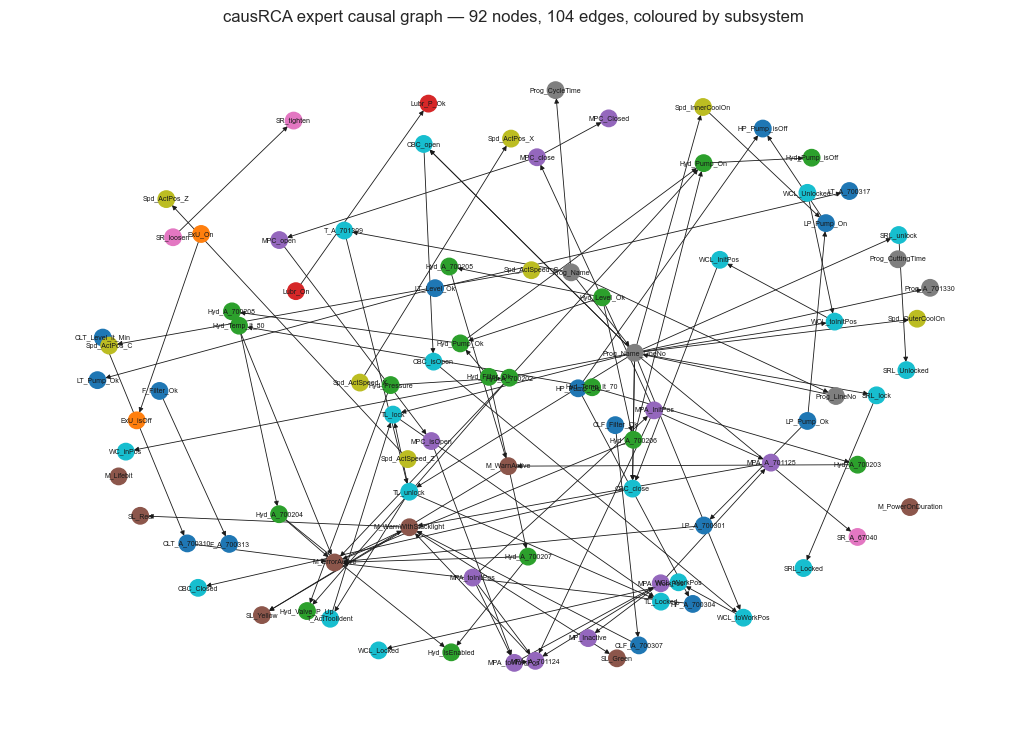

In [10]:
# Subsystem structure of the ground-truth graph
node_meta = causrca.load_node_table().set_index("label")
subsystem = node_meta["path"].str.split("/").str[1]
colors = subsystem.astype("category").cat.codes

pos = nx.spring_layout(G, seed=3, k=0.6)
fig, ax = plt.subplots(figsize=(13, 9))
nx.draw_networkx(
    G, pos, ax=ax, node_size=140, font_size=5, arrowsize=7, width=0.6,
    node_color=[colors.get(n, -1) for n in G.nodes], cmap="tab10",
)
ax.set_title("causRCA expert causal graph — 92 nodes, 104 edges, coloured by subsystem")
ax.axis("off")
plt.show()

**PCMCI suitability.** PCMCI assumes a multivariate series sampled on a regular grid. causRCA is
an event log, so it must be resampled (forward-fill on a fixed grid — semantically correct for
CoV/OPC UA data). Two properties matter:

1. *Inter-event times* — how fine must the grid be to not miss dynamics?
2. *Variable types* — PCMCI's default `ParCorr` test assumes continuous data; binary
   alarms/states need `CMIsymb`/`RegressionCI` or a mixed-data strategy.

One documented caveat (dataset README): OPC UA timestamps reflect *publish* time, so exact
event ordering across variables within short windows is not guaranteed.

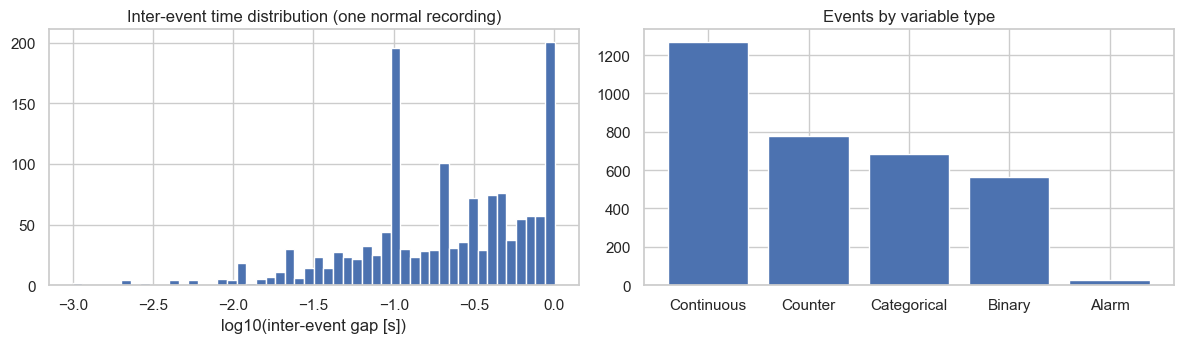

Median gap between events: 214 ms | 95th pct: 1.00 s
Numeric variables: 11/92 — the rest are boolean/categorical -> mixed-type CI tests needed


In [11]:
ev = causrca.load_event_log(real_op_files[0])
gaps = ev["time_s"].sort_values().diff().dropna()
gaps = gaps[gaps > 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(np.log10(gaps), bins=50)
axes[0].set_xlabel("log10(inter-event gap [s])")
axes[0].set_title("Inter-event time distribution (one normal recording)")
axes[1].bar(*zip(*sample_log["type"].value_counts().items()))
axes[1].set_title("Events by variable type")
plt.tight_layout()
plt.show()

print(f"Median gap between events: {gaps.median()*1000:.0f} ms | 95th pct: {gaps.quantile(0.95):.2f} s")
n_cont = (nodes['datatype'].str.contains('float|int', case=False, na=False)).sum()
print(f"Numeric variables: {n_cont}/{len(nodes)} — the rest are boolean/categorical -> mixed-type CI tests needed")

Wide matrix: 525 time steps x 74 variables (T x N)
NaN share after forward-fill: 0.0% (leading values before first event)
Variables with >1 observed state in this recording: 52/74


/Users/shwetabambal/Documents/myrepos/causalai-in-PdM/src/causalpdm/causrca.py:101: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .ffill()


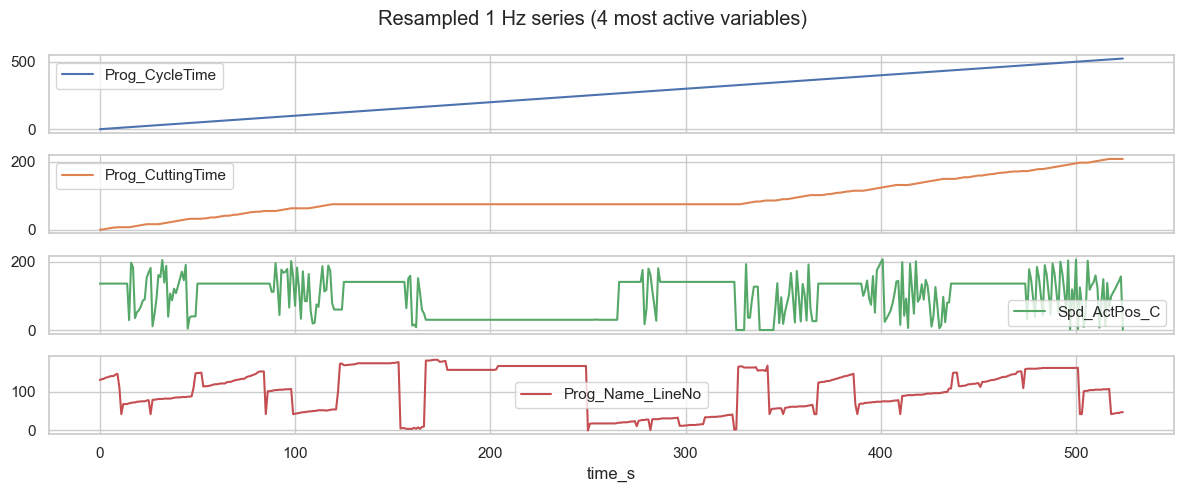

In [12]:
# Resampling demo: 1 Hz regular grid, fully numeric — direct PCMCI input format
wide = causrca.to_wide(ev, freq_s=1.0)
print(f"Wide matrix: {wide.shape[0]} time steps x {wide.shape[1]} variables (T x N)")
print(f"NaN share after forward-fill: {wide.isna().mean().mean():.1%} (leading values before first event)")
active = wide.nunique().sort_values(ascending=False)
print(f"Variables with >1 observed state in this recording: {(active > 1).sum()}/{wide.shape[1]}")
wide[active.head(4).index].plot(subplots=True, figsize=(12, 5), title="Resampled 1 Hz series (4 most active variables)")
plt.tight_layout(); plt.show()

### 3.2 Root Cause Analysis

Every fault run is labelled at three levels: (i) the *causing variables* that were manipulated,
(ii) the *alarms* expected to fire, and (iii) a textual *diagnosis*. Together with the ground-truth
timing this supports supervised **and** unsupervised RCA evaluation.

In [13]:
scenarios = (
    fault_runs.groupby(["group", "exp_id"])
    .agg(
        runs=("run", "size"),
        causing_vars=("manipulated_vars", "first"),
        diagnosis=("diagnosis", "first"),
    )
    .reset_index()
)
print(f"{len(scenarios)} fault scenarios | {fault_runs['manipulated_vars'].explode().nunique()} distinct causing variables")
scenarios

19 fault scenarios | 14 distinct causing variables


,group,exp_id,runs,causing_vars,diagnosis
0,coolant,exp_22,6,"[HP_Pump_Ok, LT_Level_Ok]",Leakage in coolant system.
1,coolant,exp_27,7,"[CLT_Level_lt_Min, HP_Pump_Ok]",Leakage in coolant system.
2,coolant,exp_28,6,"[CLF_Filter_Ok, F_Filter_Ok, LP_Pump_Ok]",Highly Contaminated Coolant.
3,coolant,exp_35,6,"[CLF_Filter_Ok, LP_Pump_Ok]",Highly Contaminated Coolant.
4,hydraulics,exp_10,5,"[Hyd_Temp_lt_70, Hyd_Temp_lt_80]",Hydraulic oil cooler defective.
5,hydraulics,exp_12,5,[Hyd_Level_Ok],Leakage in hydraulics system
6,hydraulics,exp_13,4,[Hyd_Pump_Ok],Hydraulic pump motor fails
7,hydraulics,exp_14,4,"[Hyd_Level_Ok, Hyd_Pressure]",Leakage in hydraulics system
8,hydraulics,exp_15,5,"[Hyd_Temp_lt_70, Hyd_Temp_lt_80, Hyd_Pressure]",Leakage in hydraulics system
9,hydraulics,exp_18,5,"[Hyd_Level_Ok, Hyd_Pump_Ok]",Leakage in hydraulics system


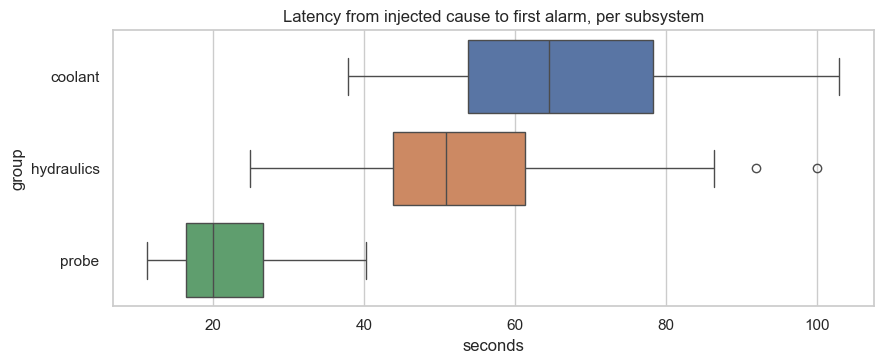

,detection_latency_s,diagnosis_latency_s
group,,
coolant,64.5,79.7
hydraulics,50.9,63.4
probe,19.9,44.4


In [14]:
# Detection and diagnosis latency: how long after the injected cause do alarms/diagnosis follow?
lat = fault_runs.assign(
    detection_latency_s=fault_runs["alarms_detected_s"] - fault_runs["cause_start_s"],
    diagnosis_latency_s=fault_runs["diagnosis_s"] - fault_runs["cause_start_s"],
)
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=lat, x="detection_latency_s", y="group", hue="group", ax=ax, legend=False)
ax.set_title("Latency from injected cause to first alarm, per subsystem")
ax.set_xlabel("seconds")
plt.tight_layout(); plt.show()
lat.groupby("group")[["detection_latency_s", "diagnosis_latency_s"]].median().round(1)

### 3.3 Interventions

The fault runs *are* interventions in the do-calculus sense: the digital twin sets specific
variables (`do(HP_Pump_Ok = False)`) while the physical controller reacts. We verify that the
manipulated variables actually change in the recorded data at the documented time — i.e. the
intervention labels are consistent with the signals.

Runs containing events for their manipulated variables: 100/100
Lag between labelled cause start and nearest manipulated-variable change:
count    100.0
mean      28.5
std       17.0
min        2.4
25%        9.6
50%       32.0
75%       42.7
max       61.5
dtype: float64


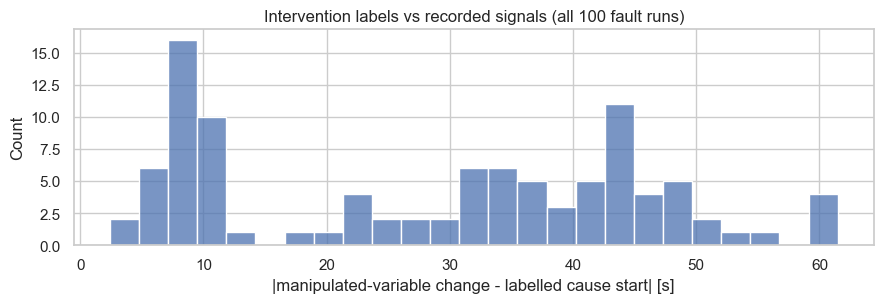

In [15]:
def injection_lag(row):
    # Seconds between the labelled cause start and the nearest recorded
    # change event of a manipulated variable.
    ev = causrca.load_event_log(row["csv_path"])
    changed = ev[ev["node"].isin(row["manipulated_vars"])]
    if changed.empty:
        return np.nan
    return float((changed["time_s"] - row["cause_start_s"]).abs().min())

lags = fault_runs.apply(injection_lag, axis=1)
print(f"Runs containing events for their manipulated variables: {lags.notna().sum()}/{len(fault_runs)}")
print(f"Lag between labelled cause start and nearest manipulated-variable change:")
print(lags.describe().round(1))

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.histplot(lags, bins=25, ax=ax)
ax.set_xlabel("|manipulated-variable change - labelled cause start| [s]")
ax.set_title("Intervention labels vs recorded signals (all 100 fault runs)")
plt.tight_layout(); plt.show()

**Finding.** Every fault run contains change events for its manipulated variables, and the
nearest change lies within ~60 s of the labelled `cause_start_at` (median 32 s). The offset is
systematic, not noise: the label marks when the twin *starts* the fault script, while the
variable's recorded state change reflects when the physical effect materialises (e.g. a tank
level takes time to fall below its threshold). For intervention experiments this means the
labels are trustworthy, but analyses should treat `cause_start_at` as the start of a fault
*window*, not an instantaneous switch.

### 3.4 Counterfactual XAI

Counterfactual reasoning needs (a) a causal structure to build an SCM on, and (b) a way to check
counterfactual claims. causRCA provides both ingredients better than any purely observational set:

- the **expert graph** gives the SCM skeleton;
- **170 normal runs of the same machine** give the factual baseline distribution;
- **repeated runs of the same fault scenario** approximate "the same situation, replayed" —
  the closest a public PdM dataset gets to twin-world counterfactual validation.

Below: a manipulated variable's behaviour under normal operation vs under its fault scenario —
the factual/counterfactual contrast is directly observable.

/Users/shwetabambal/Documents/myrepos/causalai-in-PdM/src/causalpdm/causrca.py:101: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .ffill()
/Users/shwetabambal/Documents/myrepos/causalai-in-PdM/src/causalpdm/causrca.py:101: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .ffill()


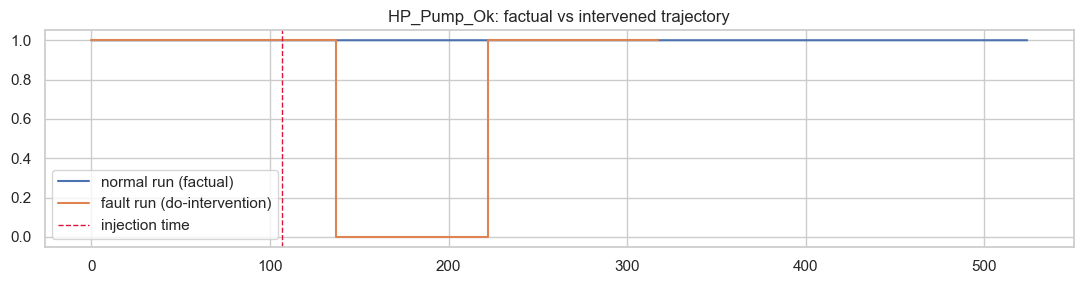

In [16]:
var = fault_runs.iloc[0]["manipulated_vars"][0]
fault_wide = causrca.to_wide(causrca.load_event_log(fault_runs.iloc[0]["csv_path"]))
normal_wide = causrca.to_wide(causrca.load_event_log(real_op_files[0]))

fig, ax = plt.subplots(figsize=(11, 3))
if var in normal_wide:
    ax.step(normal_wide.index, normal_wide[var], where="post", label="normal run (factual)")
ax.step(fault_wide.index, fault_wide[var], where="post", label="fault run (do-intervention)")
ax.axvline(fault_runs.iloc[0]["cause_start_s"], color="crimson", ls="--", lw=1, label="injection time")
ax.set_title(f"{var}: factual vs intervened trajectory")
ax.legend(); plt.tight_layout(); plt.show()

### 3.5 Actionable recommendations / dashboard suitability

Actionability requires *interpretable* variables. Every causRCA node has an OPC UA path, a
human-readable comment and a subsystem; every edge has a mechanism description ("clogged filter
triggers stacklight warning"). A recommendation like "replace the coolant fleece filter" can be
read directly off the graph — no de-anonymisation needed.

In [17]:
print("Example of mechanism-level documentation available for a dashboard:")
edges.loc[edges["comment"].notna(), ["source_label", "target_label", "comment"]].head(8)

Example of mechanism-level documentation available for a dashboard:


,source_label,target_label,comment
0,CLF_A_700307,M_WarnWithStacklight,Clogged coolant filter triggers a warning with...
1,CLF_Filter_Ok,CLF_A_700307,When Filter_OK=False for at least 5 seconds ->...
2,F_Filter_Ok,F_A_700313,When Fleece_Filter_Ok=False for at least 5 sec...
3,HP_A_700304,M_ErrorActive,High pressure pump motor protection alarm trig...
4,HP_Pump_Ok,HP_A_700304,When HP_Pump_Ok=False -> Alarm 700304 is trigg...
5,HP_Pump_Ok,HP_Pump_isOff,"When HP_Pump_Ok=False, then HP_Pump_isOff=True..."
6,LT_Level_Ok,LT_A_700317,When LT_Level_Ok=False -> Alarm 700317 is trig...
7,LT_Level_Ok,LT_Pump_Ok,"When LT_Level_Ok=False -> LT_Pump_Ok=False, i...."


## 4. Verdict — causRCA

| Workflow stage | Support | Evidence |
|---|---|---|
| Causal discovery | **Strong** | Expert ground-truth DAG (92 nodes / 104 edges) → quantitative benchmarking possible |
| Root cause analysis | **Strong** | 100 labelled fault runs, 19 scenarios, causing variables + diagnosis + timing |
| Interventions | **Strong (unique)** | Faults are literal do-interventions on known variables, verified consistent with signals |
| Counterfactual XAI | **Good** | SCM skeleton from expert graph; repeated runs + 170 normal baselines for validation |
| Actionable recommendations | **Strong** | Fully interpretable variables and mechanism-annotated edges |

**Caveats to carry into the thesis proposal**
1. Event-log format ⇒ resampling step required before PCMCI (implemented here in ~30 lines; forward-fill is semantically correct for CoV data).
2. Mixed variable types (many binary alarms/states) ⇒ PCMCI needs mixed-data CI tests, not plain `ParCorr`.
3. OPC UA publish-time caveat ⇒ exact cross-variable ordering at sub-second scale is not guaranteed (documented by the authors).
4. Recordings are minutes long (not months) ⇒ per-recording T is modest; discovery should pool recordings.
5. Young dataset (2025): no established SOTA baselines yet — a risk *and* an opportunity for novelty.